In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")
os.makedirs("../report/figures", exist_ok=True)

df = pd.read_csv("C:\\Users\\Nico\\Documents\\The Power MBA\\Proyecto Final\\cs2-pro-scene-analysis\\data\\processed\\cs2_final_dataset.csv", parse_dates=["datetime"])
win = df[df["map_win"] == 1]
lose = df[df["map_win"] == 0]
print(len(win), len(lose))

60285 58820


adr asimetría 0.38 | curtosis 0.42
kast asimetría -0.37 | curtosis 0.33


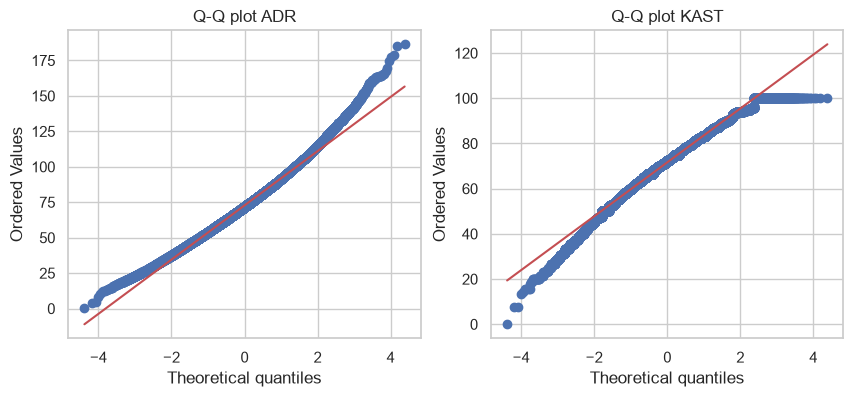

In [3]:
for col in ["adr", "kast"]:
    print(col, "asimetría", round(df[col].skew(), 2), "| curtosis", round(df[col].kurt(), 2))

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
stats.probplot(df["adr"], dist="norm", plot=ax[0]); ax[0].set_title("Q-Q plot ADR")
stats.probplot(df["kast"], dist="norm", plot=ax[1]); ax[1].set_title("Q-Q plot KAST")
fig.savefig("../report/figures/04_qqplots.png", dpi=120, bbox_inches="tight")
plt.show()

In [4]:
def comparar(col):
    t, p_t = stats.ttest_ind(win[col], lose[col], equal_var=False)
    u, p_u = stats.mannwhitneyu(win[col], lose[col])
    sd = np.sqrt((win[col].var() + lose[col].var()) / 2)
    return {
        "variable": col,
        "dif_medias": round(win[col].mean() - lose[col].mean(), 2),
        "p_welch": p_t,
        "p_mannwhitney": p_u,
        "cohen_d": round((win[col].mean() - lose[col].mean()) / sd, 2),
        "AUC": round(u / (len(win) * len(lose)), 3),
    }

tabla = pd.DataFrame([comparar(c) for c in ["adr", "kast", "kills", "assists", "deaths"]])
print(tabla.to_string(index=False))

variable  dif_medias  p_welch  p_mannwhitney  cohen_d   AUC
     adr       12.55      0.0            0.0     0.69 0.685
    kast       12.64      0.0            0.0     1.24 0.810
   kills        3.01      0.0            0.0     0.57 0.670
 assists        1.08      0.0            0.0     0.40 0.619
  deaths       -3.09      0.0            0.0    -0.78 0.263


adr        0.327
kast       0.528
kills      0.273
deaths    -0.362
assists    0.196
map_win    1.000
Name: map_win, dtype: float64
adr        0.320
kast       0.537
kills      0.295
deaths    -0.412
assists    0.208
map_win    1.000
Name: map_win, dtype: float64


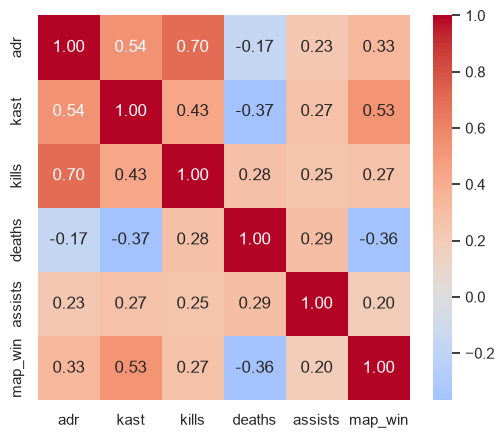

In [5]:
cols = ["adr", "kast", "kills", "deaths", "assists", "map_win"]
pear = df[cols].corr()
spear = df[cols].corr(method="spearman")
print(pear["map_win"].round(3))
print(spear["map_win"].round(3))

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(pear, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
fig.savefig("../report/figures/05_correlaciones.png", dpi=120, bbox_inches="tight")
plt.show()

In [6]:
for col in ["adr", "kast"]:
    grupos = [g[col].values for _, g in df.groupby("tier")]
    h, p = stats.kruskal(*grupos)
    print(col, "Kruskal H =", round(h, 1), "| p =", p, "| epsilon² =", round(h / (len(df) - 1), 4))

auc_tier = []
for tier, g in df.groupby("tier"):
    fila = {"tier": tier}
    for col in ["adr", "kast"]:
        u, _ = stats.mannwhitneyu(g.loc[g.map_win == 1, col], g.loc[g.map_win == 0, col])
        fila[f"AUC_{col}"] = round(u / ((g.map_win == 1).sum() * (g.map_win == 0).sum()), 3)
    auc_tier.append(fila)
print(pd.DataFrame(auc_tier).to_string(index=False))

adr Kruskal H = 70.0 | p = 6.297556103436229e-16 | epsilon² = 0.0006
kast Kruskal H = 1.6 | p = 0.45598198811246193 | epsilon² = 0.0
 tier  AUC_adr  AUC_kast
    1    0.686     0.813
    2    0.682     0.804
    3    0.690     0.819


In [7]:
X = df[["adr", "kast"]]
Xz = (X - X.mean()) / X.std()
A = np.column_stack([np.ones(len(Xz)), Xz.values])
coef, *_ = np.linalg.lstsq(A, df["map_win"].values, rcond=None)

pred = A @ coef
r2 = 1 - ((df["map_win"] - pred) ** 2).sum() / ((df["map_win"] - df["map_win"].mean()) ** 2).sum()
print(dict(zip(["const", "adr", "kast"], coef.round(3))), "| R2:", round(r2, 3))

{'const': np.float64(0.506), 'adr': np.float64(0.03), 'kast': np.float64(0.248)} | R2: 0.281


In [8]:
eq = (df.groupby(["game_id", "side"])
        .agg(adr=("adr", "mean"), kast=("kast", "mean"), win=("map_win", "first"))
        .unstack("side").dropna())

dif = pd.DataFrame({
    "d_adr": eq[("adr", "team1")] - eq[("adr", "team2")],
    "d_kast": eq[("kast", "team1")] - eq[("kast", "team2")],
    "team1_gana": eq[("win", "team1")],
})
print(len(dif))

for col in ["d_adr", "d_kast"]:
    u, _ = stats.mannwhitneyu(dif.loc[dif.team1_gana == 1, col], dif.loc[dif.team1_gana == 0, col])
    n1, n0 = (dif.team1_gana == 1).sum(), (dif.team1_gana == 0).sum()
    acierta = ((dif[col] > 0) == (dif.team1_gana == 1)).mean()
    print(col, "AUC", round(u / (n1 * n0), 3), "| acierta el ganador:", round(acierta, 3))

12209
d_adr AUC 0.967 | acierta el ganador: 0.903
d_kast AUC 0.957 | acierta el ganador: 0.882


In [9]:
sub = df[df["has_career_stats"]].copy()
print(len(sub))

for c in ["career_rating", "career_kast", "career_maps", "num_teams"]:
    print(c, {v: round(stats.spearmanr(sub[c], sub[v])[0], 3) for v in ["adr", "kast", "map_win"]})

sub["experiencia"] = pd.qcut(sub["career_maps"], 3, labels=["baja", "media", "alta"])
print(sub.groupby("experiencia", observed=True)[["adr", "kast", "map_win"]].mean().round(3))

48965
career_rating {'adr': np.float64(0.15), 'kast': np.float64(0.12), 'map_win': np.float64(0.035)}
career_kast {'adr': np.float64(0.092), 'kast': np.float64(0.126), 'map_win': np.float64(0.023)}
career_maps {'adr': np.float64(-0.01), 'kast': np.float64(-0.011), 'map_win': np.float64(0.011)}
num_teams {'adr': np.float64(-0.04), 'kast': np.float64(-0.027), 'map_win': np.float64(-0.002)}
                adr    kast  map_win
experiencia                         
baja         72.450  71.671    0.505
media        72.244  71.984    0.531
alta         72.423  71.543    0.510


In [11]:
import statsmodels.api as sm

modelo = sm.Logit(df["map_win"], sm.add_constant(Xz)).fit(disp=0)
print(modelo.summary().tables[1])
print(np.exp(modelo.params).round(2))

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0049      0.007     -0.708      0.479      -0.018       0.009
adr            0.1754      0.008     20.966      0.000       0.159       0.192
kast           1.4409      0.010    137.325      0.000       1.420       1.462
const    1.00
adr      1.19
kast     4.22
dtype: float64
